# Assignment 6

Same experiment - different representation. Dataset contains same data, but it uses vgg16 embeddings instead of handcrafted morpho characteristics. 
>week6\large_object_vgg3d_embeddings_processed.csv

## Task

Build and evaluate a neural-network classifier for `cell_type` using the VGG3D embedding representation. Compare it with at least one simpler model and explain what the results mean biologically and statistically.

Do not use `sample_group` as a predictive feature. Use it only to construct leakage-safe splits.

## Required sections

## Questions for the report

1. Did the embedding space show visible separation between the cell types?
2. Which learning rate and architecture performed best, and what evidence supports that choice?
3. Did the MLP overfit? Use the training and validation curves to justify your answer.
4. Which regularization method was most useful?
5. How did the MLP compare with logistic regression and XGBoost?
7. Which cell types were most frequently confused?
8. What additional biological or technical information would help explain the errors?

## Deliverables

- completed notebook;
- short report answering the questions above;
- one table comparing the final models;
- figures for the embedding visualization, learning curves, and confusion matrix;
- a brief statement of limitations and possible next steps.

In [1]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import optuna
import optuna
import torch
import torch.nn as nn
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold,
)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier
import plotly.express as px

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE)


Device: mps


### 1. Data inspection and preparation checklist

Since data is the same no need to write detailed report but still - check if everything is in order(just in case)

In [2]:
df = pd.read_csv("large_object_vgg3d_embeddings_processed.csv")
df.head()

,cell_type,sample_group,vgg_emb_000,vgg_emb_001,vgg_emb_002,vgg_emb_003,vgg_emb_004,vgg_emb_005,vgg_emb_006,vgg_emb_007,...,vgg_emb_118,vgg_emb_119,vgg_emb_120,vgg_emb_121,vgg_emb_122,vgg_emb_123,vgg_emb_124,vgg_emb_125,vgg_emb_126,vgg_emb_127
0,m0,sample_group_079,0.039772,0.0,1.179048,0.0,0.0,0.0,1.221995,0.0,...,0.0,0.0,0.0,0.797191,1.709197,0.0,0.777199,0.0,1.924863,0.0
1,m0,sample_group_079,0.000000,0.0,4.433527,0.0,0.0,0.0,5.810353,0.0,...,0.0,0.0,0.0,3.935624,6.289729,0.0,2.987612,0.0,8.424339,0.0
2,m0,sample_group_079,0.000000,0.0,4.108049,0.0,0.0,0.0,5.343654,0.0,...,0.0,0.0,0.0,3.621442,5.779456,0.0,2.740911,0.0,7.669261,0.0
3,m0,sample_group_079,0.000000,0.0,4.042331,0.0,0.0,0.0,5.283560,0.0,...,0.0,0.0,0.0,3.587561,5.783239,0.0,2.660382,0.0,7.480461,0.0
4,m0,sample_group_079,0.000000,0.0,2.474535,0.0,0.0,0.0,3.063431,0.0,...,0.0,0.0,0.0,2.021839,3.586300,0.0,1.637182,0.0,4.486126,0.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Columns: 130 entries, cell_type to vgg_emb_127
dtypes: float64(128), str(2)
memory usage: 393.8 KB


In [4]:
df.isna().sum().sum()

np.int64(0)

In [5]:
CELL_TYPE = "cell_type"
SAMPLE_GROUP = "sample_group"

features = df.columns[~df.columns.isin([CELL_TYPE, SAMPLE_GROUP])]
features

Index(['vgg_emb_000', 'vgg_emb_001', 'vgg_emb_002', 'vgg_emb_003',
       'vgg_emb_004', 'vgg_emb_005', 'vgg_emb_006', 'vgg_emb_007',
       'vgg_emb_008', 'vgg_emb_009',
       ...
       'vgg_emb_118', 'vgg_emb_119', 'vgg_emb_120', 'vgg_emb_121',
       'vgg_emb_122', 'vgg_emb_123', 'vgg_emb_124', 'vgg_emb_125',
       'vgg_emb_126', 'vgg_emb_127'],
      dtype='str', length=128)

In [6]:
features = features[~df[features].std().eq(0)]
features.size

91

In [7]:
X = df[features]
X.head()

,vgg_emb_000,vgg_emb_002,vgg_emb_005,vgg_emb_006,vgg_emb_008,vgg_emb_009,vgg_emb_010,vgg_emb_011,vgg_emb_012,vgg_emb_013,...,vgg_emb_113,vgg_emb_114,vgg_emb_116,vgg_emb_117,vgg_emb_121,vgg_emb_122,vgg_emb_124,vgg_emb_125,vgg_emb_126,vgg_emb_127
0,0.039772,1.179048,0.0,1.221995,1.287161,0.0,0.0,0.0,0.328466,1.796104,...,0.0,1.772306,0.295292,0.893132,0.797191,1.709197,0.777199,0.0,1.924863,0.0
1,0.000000,4.433527,0.0,5.810353,5.679070,0.0,0.0,0.0,1.328905,6.663649,...,0.0,7.227830,0.385759,3.204363,3.935624,6.289729,2.987612,0.0,8.424339,0.0
2,0.000000,4.108049,0.0,5.343654,5.157644,0.0,0.0,0.0,1.135407,6.089701,...,0.0,6.589556,0.342752,2.966972,3.621442,5.779456,2.740911,0.0,7.669261,0.0
3,0.000000,4.042331,0.0,5.283560,5.123363,0.0,0.0,0.0,1.147058,6.012712,...,0.0,6.451838,0.318679,2.946192,3.587561,5.783239,2.660382,0.0,7.480461,0.0
4,0.000000,2.474535,0.0,3.063431,3.048964,0.0,0.0,0.0,0.752677,3.735067,...,0.0,3.997463,0.349789,1.817329,2.021839,3.586300,1.637182,0.0,4.486126,0.0


In [8]:
y = df[CELL_TYPE]
y.head()

0    m0
1    m0
2    m0
3    m0
4    m0
Name: cell_type, dtype: str

In [9]:
groups = df[SAMPLE_GROUP]
groups.head()

0    sample_group_079
1    sample_group_079
2    sample_group_079
3    sample_group_079
4    sample_group_079
Name: sample_group, dtype: str

### 2. Exploratory analysis

Show:

- class counts for `m0`, `m1`, and `m2`;
- the distribution of selected embedding features;
- missingness by feature and by row;
- a two-dimensional t-SNE or UMAP visualization coloured by `cell_type`.

Treat t-SNE/UMAP as exploratory visualizations, not as test-set evaluation.

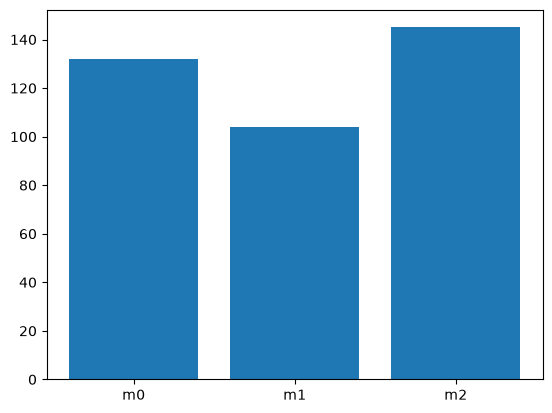

In [10]:
counts = y.value_counts().sort_index()
plt.bar(counts.index, counts)
plt.show()

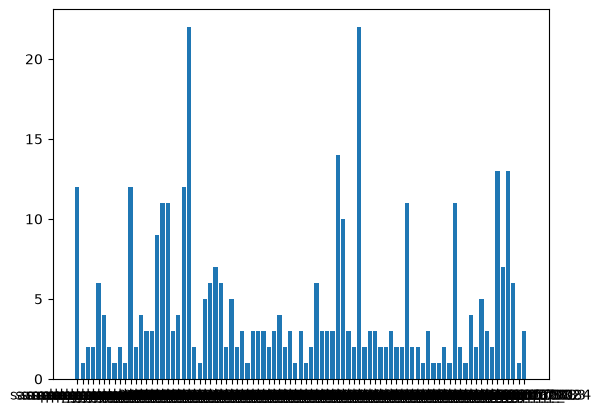

In [11]:
counts = groups.value_counts().sort_index()
plt.bar(counts.index, counts)
plt.show()

In [12]:
stats = pd.DataFrame({
  "mean": X.mean(),
  "var": X.var(),
})

fig = px.scatter(
  stats.reset_index(names="feature"),
  x="mean", y="var",
  hover_name="feature",
  labels={"mean": "Mean", "var": "Variance"},
  title="Mean vs variance per feature",
)

fig.show()

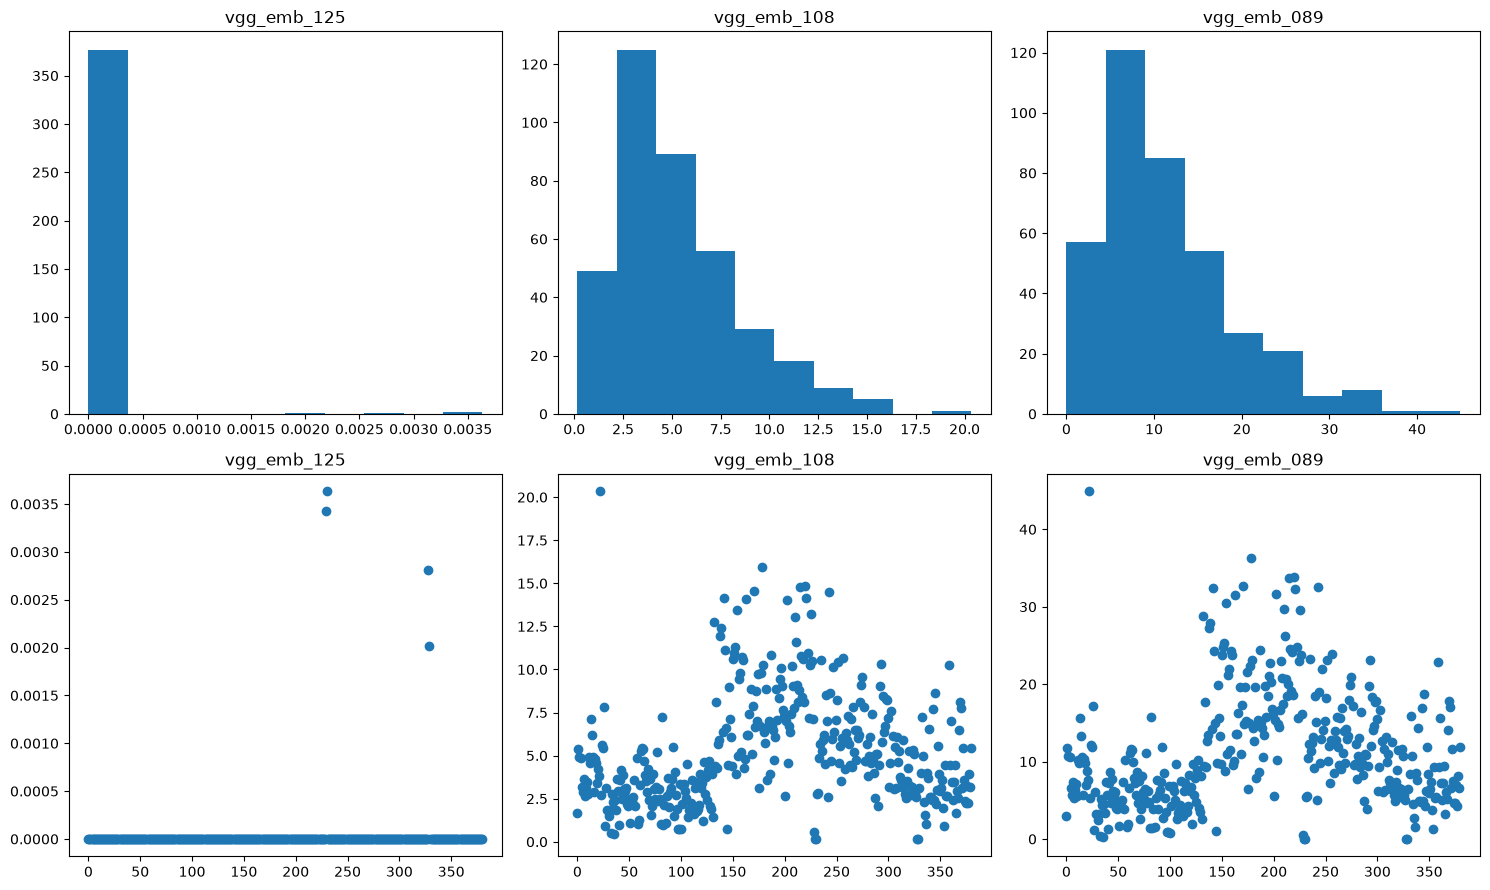

In [13]:
fig, axs = plt.subplots(ncols=3, nrows=2, figsize=(15, 9))

def plot_feature(n, feature):
  axs[0][n].hist(X[feature])
  axs[0][n].set_title(feature)

  axs[1][n].scatter(X.index, X[feature])
  axs[1][n].set_title(feature)

plot_feature(0, 'vgg_emb_125')
plot_feature(1, 'vgg_emb_108')
plot_feature(2, 'vgg_emb_089')

fig.tight_layout()
plt.show()

In [14]:
X_scaled = StandardScaler().fit_transform(X)

tsne = TSNE(
  n_components=2, perplexity=30, init="pca",
  learning_rate="auto", random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(X_scaled)
tsne_df = pd.DataFrame(X_tsne, columns=["tSNE1", "tSNE2"], index=X.index).join(y).join(groups)

In [15]:
fig = px.scatter(
  tsne_df.reset_index(), x="tSNE1", y="tSNE2", color=CELL_TYPE,
  hover_name=tsne_df.index.name or "index",
  title=f"t-SNE colored by {CELL_TYPE}",
  opacity=0.8,
  width=600, height=500,
)
fig.update_traces(marker_size=10)
fig.show()

In [16]:
fig = px.scatter(
  tsne_df.reset_index(), x="tSNE1", y="tSNE2", color=SAMPLE_GROUP,
  hover_name=tsne_df.index.name or "index",
  title=f"t-SNE colored by {SAMPLE_GROUP}",
  opacity=0.8,
  width=600, height=500,
)
fig.update_traces(marker_size=10)
fig.show()

### 3. Leakage-safe splitting and preprocessing

Create training, validation, and test partitions, be sure that you dont introduce any leakege.

In [17]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
split = outer.split(X, y, groups)
trainval_idx, test_idx = next(split)

inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
split = inner.split(X.iloc[trainval_idx], y.iloc[trainval_idx], groups.iloc[trainval_idx])
tr, va = next(split)
train_idx, val_idx = trainval_idx[tr], trainval_idx[va]

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val,   y_val   = X.iloc[val_idx],   y.iloc[val_idx]
X_test,  y_test  = X.iloc[test_idx],  y.iloc[test_idx]

In [18]:
g_tr, g_va, g_te = (set(groups.iloc[i]) for i in (train_idx, val_idx, test_idx))
assert not (g_tr & g_va or g_tr & g_te or g_va & g_te)

pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "val":   y_val.value_counts(normalize=True),
    "test":  y_test.value_counts(normalize=True),
}).sort_index()

,train,val,test
cell_type,,,
m0,0.348018,0.337662,0.350649
m1,0.273128,0.272727,0.272727
m2,0.378855,0.389610,0.376623


### 4. Baseline and MLP model

Train a simple baseline, such as multinomial logistic regression, followed by a PyTorch MLP

Report training and validation loss and accuracy across epochs.

### 5. Experiments

Perform experiments corresponding to the Week 6 explanations:

- compare at least three learning rates;
- compare at least two network capacities;
- identify possible overfitting from learning curves;
- compare weight decay and dropout;
- demonstrate early stopping;
- explain which configuration you select and why.

Keep the random seed fixed when comparing configurations.

### 6. Classical comparison

Compare the selected MLP with:

- logistic regression;
- XGBoost with a small, validation-only hyperparameter search.

### 7. Evaluation

Evaluate the final selected models on the untouched test partition using:

- balanced accuracy;
- macro F1 score;
- a confusion matrix;
- a short class-by-class error analysis.

Do not select the final model using test performance.